# PROYECTO ATHENA — Hito 3: Adquisición de Datos Financieros

**Grado en Ciencia de Datos Aplicada — Universitat Oberta de Catalunya (UOC)**  
Autor: Álvaro Sánchez Mendoza | Tutor: Carlos Gaitán Poyatos  
Versión: 1.0.0

---

## Descripción

Este notebook implementa el pipeline de adquisición de datos financieros del Hito 3.
Cubre todas las actividades completadas en este hito:

| Actividad | Estado |
|-----------|--------|
| Conexión con la API de Yahoo Finance (yfinance) | ✅ Completado |
| Descarga de series históricas de precios ajustados | ✅ Completado |
| Cálculo de rendimientos logarítmicos diarios | ✅ Completado |
| Sistema de caché local en CSV | ✅ Completado |
| Estadísticas descriptivas básicas (EDA) | ✅ Completado |
| Preprocesado avanzado (nulos, outliers, reindexado) | ⏳ Hito siguiente |

---

## Estructura del notebook

1. Instalación y verificación de dependencias  
2. Importaciones y configuración  
3. Definición de constantes y tickers  
4. Clase `DataAcquisition` — implementación completa  
5. Demostración del pipeline: descarga de precios  
6. Cálculo de rendimientos logarítmicos  
7. Estadísticas descriptivas anualizadas  
8. Visualización exploratoria de los datos  
9. Resumen y outputs para el Hito 4  


## 1. Instalación y verificación de dependencias

Ejecuta la siguiente celda para instalar las dependencias necesarias.
Si ya están instaladas, el comando no produce ningún efecto.

In [1]:
# Instalación de dependencias (descomentar si es necesario)
# !pip install yfinance pandas numpy matplotlib

# Verificación de versiones instaladas
import importlib

dependencias = {
    'yfinance': '0.2.28',
    'pandas':   '2.0.0',
    'numpy':    '1.26.0',
}

print('Verificación de dependencias del Hito 3:')
print('-' * 45)
for paquete, version_min in dependencias.items():
    try:
        mod = importlib.import_module(paquete)
        version = getattr(mod, '__version__', 'desconocida')
        print(f'  {paquete:<12}: {version:<10} (mínimo requerido: {version_min})')
    except ImportError:
        print(f'  {paquete:<12}: NO INSTALADO — ejecuta: pip install {paquete}')
print('-' * 45)
print('Verificación completada.')


Verificación de dependencias del Hito 3:
---------------------------------------------
  yfinance    : 1.2.0      (mínimo requerido: 0.2.28)
  pandas      : 2.3.3      (mínimo requerido: 2.0.0)
  numpy       : 2.0.2      (mínimo requerido: 1.26.0)
---------------------------------------------
Verificación completada.


## 2. Importaciones y configuración

Importamos todas las librerías necesarias y configuramos el sistema de logging.

In [2]:
import logging
import warnings
from datetime import datetime
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Suprimir avisos de deprecación externos
warnings.filterwarnings('ignore', category=FutureWarning)

# Configuración del logger para el notebook
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s  [%(levelname)s]  %(message)s',
    datefmt='%H:%M:%S',
)
logger = logging.getLogger('athena.hito3')

# Configuración visual de pandas
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 120)

# Estilo de gráficos
plt.rcParams.update({
    'figure.figsize':   (14, 5),
    'axes.spines.top':  False,
    'axes.spines.right':False,
    'axes.grid':        True,
    'grid.alpha':       0.3,
    'font.size':        10,
})

print('Importaciones completadas correctamente.')


Importaciones completadas correctamente.


## 3. Constantes y configuración de tickers

Definimos las listas de tickers predefinidas para el IBEX 35 y el S&P 500,
así como las constantes del módulo.

In [3]:
# ── Tickers del IBEX 35 (sufijo .MC = Mercado Continuo español) ──
IBEX35_TICKERS = [
    'SAN.MC', 'BBVA.MC', 'TEF.MC', 'ITX.MC', 'IBE.MC',
    'REP.MC', 'ACS.MC', 'FER.MC', 'CLNX.MC', 'AENA.MC',
    'AMS.MC', 'ACX.MC', 'ELE.MC', 'GRF.MC', 'IAG.MC',
    'IDR.MC', 'INM.MC', 'MAP.MC', 'MRL.MC', 'NTGY.MC',
    'PHM.MC', 'RED.MC', 'ROVI.MC', 'SAB.MC', 'SGRE.MC',
    'SLR.MC', 'VIS.MC', 'BKT.MC', 'MEL.MC', 'MTS.MC',
]

# ── Tickers del S&P 500 (sin sufijo = bolsa estadounidense) ──
SP500_TICKERS = [
    'AAPL', 'MSFT', 'AMZN', 'GOOGL', 'META',
    'NVDA', 'TSLA', 'BRK-B', 'UNH', 'JNJ',
    'JPM', 'V', 'PG', 'XOM', 'HD',
    'MA', 'CVX', 'ABBV', 'MRK', 'KO',
    'PEP', 'LLY', 'AVGO', 'TMO', 'COST',
    'MCD', 'DHR', 'WMT', 'ACN', 'NKE',
]

# ── Constantes financieras ──
TRADING_DAYS_YEAR = 252   # días hábiles anuales estándar

print(f'IBEX35 : {len(IBEX35_TICKERS)} activos definidos')
print(f'S&P 500: {len(SP500_TICKERS)} activos definidos')
print(f'TRADING_DAYS_YEAR = {TRADING_DAYS_YEAR}')


IBEX35 : 30 activos definidos
S&P 500: 30 activos definidos
TRADING_DAYS_YEAR = 252


## 4. Clase `DataAcquisition`

Implementación de la clase principal del módulo. Encapsula toda la lógica de
conexión con Yahoo Finance, descarga y transformación de datos.

In [4]:
class DataAcquisition:
    """
    Pipeline de adquisición de datos financieros desde Yahoo Finance.

    Gestiona la conexión con la API, la descarga de series históricas de
    precios de cierre ajustados y su transformación a rendimientos
    logarítmicos diarios. Incluye sistema de caché local en CSV.

    Parameters
    ----------
    tickers : list[str]
        Símbolos bursátiles en formato Yahoo Finance.
        IBEX 35: sufijo '.MC' (ej. 'SAN.MC').
        S&P 500: sin sufijo (ej. 'AAPL').
    start : str
        Fecha de inicio en formato 'YYYY-MM-DD'.
    end : str, optional
        Fecha de fin en formato 'YYYY-MM-DD'. Defecto: hoy.
    interval : str, optional
        Frecuencia: '1d' (diario), '1wk' (semanal), '1mo' (mensual).
    cache_dir : str or Path, optional
        Directorio de caché local. None = sin persistencia.
    """

    def __init__(self, tickers, start='2019-01-01', end=None,
                 interval='1d', cache_dir=None):
        if not tickers:
            raise ValueError('La lista de tickers no puede estar vacía.')

        self.tickers  = [t.upper().strip() for t in tickers]
        self.start    = start
        self.end      = end or datetime.today().strftime('%Y-%m-%d')
        self.interval = interval

        if cache_dir is not None:
            self.cache_dir = Path(cache_dir)
            self.cache_dir.mkdir(parents=True, exist_ok=True)
        else:
            self.cache_dir = None

        logger.info(
            'DataAcquisition: %d activos | %s → %s | freq: %s',
            len(self.tickers), self.start, self.end, self.interval
        )

    # ── Descarga ─────────────────────────────────────────────────────
    def download(self, use_cache=True):
        """
        Descarga los precios de cierre ajustados desde Yahoo Finance.

        Usa caché local si está disponible para evitar descargas
        redundantes. Los precios ajustados (auto_adjust=True) incorporan
        correcciones por dividendos y splits, garantizando la
        comparabilidad temporal requerida por el modelo de Markowitz.

        Parameters
        ----------
        use_cache : bool
            Si True, carga desde CSV local si existe. Defecto True.

        Returns
        -------
        pd.DataFrame
            Precios de cierre ajustados. Índice: DatetimeIndex.
            Columnas: tickers. Latencia < 15 minutos (KPI Hito 3).
        """
        cache_path = self._cache_path('prices_raw')

        # Cargar desde caché si existe
        if use_cache and cache_path and cache_path.exists():
            logger.info('Cargando desde caché: %s', cache_path.name)
            df = pd.read_csv(cache_path, index_col=0, parse_dates=True)
            df.index.name = 'Date'
            return df

        # Descarga desde la API de Yahoo Finance
        logger.info('Descargando de Yahoo Finance: %d activos...', len(self.tickers))
        try:
            raw = yf.download(
                tickers     = self.tickers,
                start       = self.start,
                end         = self.end,
                interval    = self.interval,
                auto_adjust = True,   # precios ajustados por dividendos y splits
                progress    = False,  # sin barra de progreso en terminal
                threads     = True,   # descarga paralela multi-ticker
            )
        except Exception as exc:
            raise ConnectionError(f'Error en Yahoo Finance: {exc}') from exc

        # Extraer columna 'Close' del MultiIndex devuelto por yfinance
        if isinstance(raw.columns, pd.MultiIndex):
            prices = raw['Close'].copy()
        else:
            prices = raw[['Close']].copy()
            prices.columns = self.tickers[:1]

        if prices.empty:
            raise ValueError('La descarga no devolvió datos. Verifica los tickers.')

        prices.index = pd.to_datetime(prices.index)
        prices.index.name = 'Date'

        # Informe de calidad en el log
        self._log_report(prices)

        # Persistir en caché
        if cache_path:
            prices.to_csv(cache_path)
            logger.info('Datos guardados: %s', cache_path.name)

        return prices

    # ── Rendimientos logarítmicos ─────────────────────────────────────
    def compute_returns(self, prices):
        """
        Calcula rendimientos logarítmicos diarios: r_t = ln(P_t / P_{t-1}).

        Se prefiere el rendimiento logarítmico frente al aritmético por:
        (1) Aditividad temporal — facilita la anualización.
        (2) Simetría estadística — mejora el ajuste de modelos.
        (3) Estándar en literatura financiera de optimización.

        Parameters
        ----------
        prices : pd.DataFrame
            Precios de cierre ajustados de download().

        Returns
        -------
        pd.DataFrame
            Rendimientos diarios. Una fila menos que prices.
        """
        logger.info('Calculando rendimientos logarítmicos...')

        # ln(P_t / P_{t-1}) — .shift(1) toma el precio del día anterior
        # .iloc[1:] elimina la primera fila (NaN por ausencia de t-1)
        returns = np.log(prices / prices.shift(1)).iloc[1:]

        if returns.empty:
            raise ValueError('DataFrame de precios con menos de 2 filas.')

        logger.info(
            'Rendimientos: %d obs × %d activos | media=%.6f | std=%.6f',
            len(returns), returns.shape[1],
            returns.mean().mean(), returns.std().mean()
        )

        # Persistir en caché
        cache_path = self._cache_path('returns')
        if cache_path:
            returns.to_csv(cache_path)
            logger.info('Rendimientos guardados: %s', cache_path.name)

        return returns

    # ── Estadísticas anualizadas ──────────────────────────────────────
    def compute_annualized_stats(self, returns):
        """
        Estadísticas descriptivas anualizadas para el panel EDA.

        Returns
        -------
        pd.DataFrame
            Columnas: Rendimiento anual (%), Volatilidad anual (%),
            Ratio de Sharpe, Asimetría, Curtosis, Máx. Drawdown (%).
        """
        logger.info('Calculando estadísticas anualizadas...')
        stats = pd.DataFrame(index=returns.columns)

        # Rendimiento anual: media diaria × 252 × 100
        stats['Rendimiento anual (%)'] = (
            returns.mean() * TRADING_DAYS_YEAR * 100
        ).round(2)

        # Volatilidad anual: std diaria × √252 × 100
        stats['Volatilidad anual (%)'] = (
            returns.std() * np.sqrt(TRADING_DAYS_YEAR) * 100
        ).round(2)

        # Ratio de Sharpe sin rf=0 (comparación relativa entre activos)
        stats['Ratio de Sharpe'] = (
            stats['Rendimiento anual (%)'] /
            stats['Volatilidad anual (%)'].replace(0, np.nan)
        ).round(4)

        # Asimetría: negativa = colas izquierdas más largas (más pérdidas extremas)
        stats['Asimetría'] = returns.skew().round(4)

        # Curtosis en exceso: >0 = colas más pesadas que la normal (leptocúrtica)
        stats['Curtosis'] = returns.kurt().round(4)

        # Máximo Drawdown: mayor caída porcentual desde máximo histórico
        stats['Máx. Drawdown (%)'] = returns.apply(self._max_drawdown).round(2)

        return stats

    # ── Métodos privados ─────────────────────────────────────────────
    def _cache_path(self, name):
        """Ruta del archivo CSV de caché para un dataset dado."""
        if self.cache_dir is None:
            return None
        return self.cache_dir / f'{name}_{self.start}_{self.end}_{self.interval}.csv'

    def _log_report(self, prices):
        """Registra informe de calidad de la descarga en el log."""
        logger.info('Activos descargados: %d', prices.shape[1])
        logger.info('Período: %s → %s', prices.index.min().date(), prices.index.max().date())
        logger.info('Observaciones: %d días', len(prices))
        null_pct = prices.isna().mean() * 100
        for ticker, pct in null_pct.items():
            if pct > 0:
                logger.warning('%s: %.1f%% nulos (pendiente preprocesado)', ticker, pct)
            else:
                logger.info('%s: sin nulos', ticker)

    @staticmethod
    def _max_drawdown(series):
        """
        Máximo Drawdown: mayor caída porcentual desde máximo histórico.

        Fórmula:
            MDD = min((cum_returns - rolling_max) / rolling_max) × 100
        """
        cum_returns = (1 + series).cumprod()   # valor acumulado
        rolling_max = cum_returns.cummax()      # máximo histórico rolling
        drawdown    = (cum_returns - rolling_max) / rolling_max
        return float(drawdown.min() * 100)


print('Clase DataAcquisition definida correctamente.')


Clase DataAcquisition definida correctamente.


## 5. Configuración de la demostración

Definimos los parámetros para el caso de uso del Hito 3:
una cartera de 8 activos del IBEX 35 con 5 años de histórico.

In [5]:
# ── Parámetros del caso de uso ────────────────────────────────────
TICKERS = [
    'SAN.MC',  # Banco Santander
    'BBVA.MC', # BBVA
    'TEF.MC',  # Telefónica
    'ITX.MC',  # Inditex
    'IBE.MC',  # Iberdrola
    'REP.MC',  # Repsol
    'ACS.MC',  # ACS
    'FER.MC',  # Ferrovial
]

START_DATE = '2019-01-01'
END_DATE   = '2024-12-31'
CACHE_DIR  = Path('data/cache')

print(f'Activos seleccionados : {TICKERS}')
print(f'Período               : {START_DATE} → {END_DATE}')
print(f'Directorio de caché   : {CACHE_DIR}')


Activos seleccionados : ['SAN.MC', 'BBVA.MC', 'TEF.MC', 'ITX.MC', 'IBE.MC', 'REP.MC', 'ACS.MC', 'FER.MC']
Período               : 2019-01-01 → 2024-12-31
Directorio de caché   : data\cache


## 6. Descarga de precios de cierre ajustados

Inicializamos el pipeline y descargamos los precios históricos.
La primera ejecución conecta con Yahoo Finance; las siguientes usan la caché local.

In [6]:
# Inicializar el pipeline
pipeline = DataAcquisition(
    tickers   = TICKERS,
    start     = START_DATE,
    end       = END_DATE,
    cache_dir = CACHE_DIR,
)

# Descargar precios (use_cache=True evita descargas redundantes)
prices = pipeline.download(use_cache=True)

print('\nResultados de la descarga:')
print(f'  Shape          : {prices.shape}')
print(f'  Período real   : {prices.index.min().date()} → {prices.index.max().date()}')
print(f'  Nulos totales  : {prices.isna().sum().sum()}')


16:07:23  [INFO]  DataAcquisition: 8 activos | 2019-01-01 → 2024-12-31 | freq: 1d
16:07:23  [INFO]  Descargando de Yahoo Finance: 8 activos...
16:07:23  [INFO]  Failed to create TzCache, reason: Error creating TzCache folder: 'C:\Users\Alvaro\AppData\Local\py-yfinance' reason: [WinError 183] No se puede crear un archivo que ya existe: 'C:\\Users\\Alvaro\\AppData\\Local\\py-yfinance'. TzCache will not be used. Tip: You can direct cache to use a different location with 'set_tz_cache_location(mylocation)'
16:07:25  [INFO]  Activos descargados: 8
16:07:25  [INFO]  Período: 2019-01-02 → 2024-12-30
16:07:25  [INFO]  Observaciones: 1536 días
16:07:25  [INFO]  ACS.MC: sin nulos
16:07:25  [INFO]  BBVA.MC: sin nulos
16:07:25  [INFO]  FER.MC: sin nulos
16:07:25  [INFO]  IBE.MC: sin nulos
16:07:25  [INFO]  ITX.MC: sin nulos
16:07:25  [INFO]  REP.MC: sin nulos
16:07:25  [INFO]  SAN.MC: sin nulos
16:07:25  [INFO]  TEF.MC: sin nulos
16:07:25  [INFO]  Datos guardados: prices_raw_2019-01-01_2024-12-31_


Resultados de la descarga:
  Shape          : (1536, 8)
  Período real   : 2019-01-02 → 2024-12-30
  Nulos totales  : 0


### Inspección de los datos descargados

In [7]:
# Primeras 5 filas
print('Primeras 5 filas:')
print(prices.head())
print()

# Últimas 5 filas
print('Últimas 5 filas:')
print(prices.tail())
print()

# Info del DataFrame
print('Info del DataFrame:')
prices.info()


Primeras 5 filas:
Ticker      ACS.MC  BBVA.MC  FER.MC  IBE.MC  ITX.MC  REP.MC  SAN.MC  TEF.MC
Date                                                                       
2019-01-02 20.9031   3.1369 15.0195  5.1173 17.7379  8.9691  3.0204  4.3287
2019-01-03 20.9534   3.1453 15.0958  5.1261 17.4848  8.9817  3.0447  4.4006
2019-01-04 21.2678   3.2627 15.2781  5.1641 18.1016  9.1959  3.1586  4.4579
2019-01-07 21.3370   3.2513 15.3926  5.2036 18.2440  9.1203  3.1764  4.4982
2019-01-08 21.5571   3.2789 15.5411  5.1846 18.6394  9.1298  3.2026  4.4912

Últimas 5 filas:
Ticker      ACS.MC  BBVA.MC  FER.MC  IBE.MC  ITX.MC  REP.MC  SAN.MC  TEF.MC
Date                                                                       
2024-12-20 45.5532   8.7859 39.1696 12.3382 48.3543  9.8609  4.2283  3.6464
2024-12-23 45.4764   8.7840 39.3859 12.3665 47.7554  9.9505  4.2041  3.6325
2024-12-24 45.9563   8.7519 39.8578 12.4233 47.8231 10.0221  4.1939  3.6325
2024-12-27 46.0907   8.8653 39.9168 12.4469 48.1322 

### Estadísticas básicas de los precios descargados

In [8]:
# Estadísticas descriptivas básicas de los precios
print('Estadísticas descriptivas de los precios de cierre ajustados:')
print(prices.describe().round(2))


Estadísticas descriptivas de los precios de cierre ajustados:
Ticker    ACS.MC   BBVA.MC    FER.MC    IBE.MC    ITX.MC    REP.MC    SAN.MC    TEF.MC
count  1536.0000 1536.0000 1536.0000 1536.0000 1536.0000 1536.0000 1536.0000 1536.0000
mean     24.0400    4.7400   24.6700    8.8500   26.9300    9.3900    2.8800    3.2400
std       7.6800    2.1300    5.7100    1.7100    8.7900    2.3300    0.7600    0.6300
min       7.6900    1.6200   15.0200    5.1200   16.4700    3.7300    1.2300    1.8000
25%      18.4100    3.3700   20.8400    7.8900   20.7000    7.9300    2.3900    2.7500
50%      22.5800    3.9600   22.9700    8.8000   23.8500    9.5100    2.8400    3.1500
75%      27.1500    5.9900   27.2700    9.8100   30.9100   11.2900    3.2500    3.6900
max      46.2100   10.0600   40.3500   13.4000   54.0700   14.0000    4.6300    4.5800


### Visualización — Evolución histórica de precios (base 100)

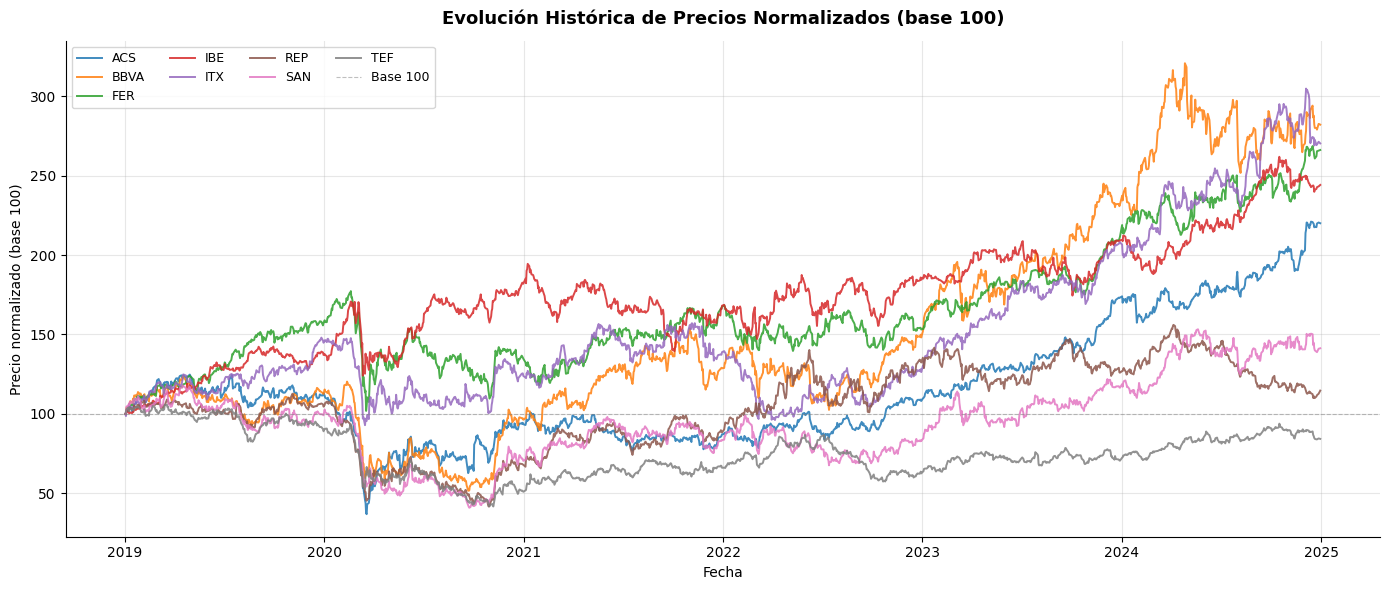

Gráfico guardado: evolucion_precios_normalizados.png


In [9]:
# Normalización de precios a base 100 en la primera fecha
# Permite comparar visualmente la evolución relativa de cada activo
prices_norm = prices / prices.iloc[0] * 100

fig, ax = plt.subplots(figsize=(14, 6))

for ticker in prices_norm.columns:
    ax.plot(prices_norm.index, prices_norm[ticker],
            label=ticker.replace('.MC', ''), linewidth=1.4, alpha=0.85)

ax.axhline(100, color='gray', linestyle='--', linewidth=0.8, alpha=0.5,
           label='Base 100')
ax.set_title('Evolución Histórica de Precios Normalizados (base 100)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Fecha')
ax.set_ylabel('Precio normalizado (base 100)')
ax.legend(ncol=4, fontsize=9, loc='upper left')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig('evolucion_precios_normalizados.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: evolucion_precios_normalizados.png')


## 7. Cálculo de rendimientos logarítmicos diarios

Los rendimientos logarítmicos diarios se calculan como:

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

donde $P_t$ es el precio de cierre ajustado en la fecha $t$.

**¿Por qué logarítmico y no aritmético?**
- **Aditividad temporal**: $\sum r_t = \ln(P_T/P_0)$, facilita la anualización.
- **Simetría**: subidas y bajadas del mismo porcentaje producen valores simétricos.
- **Estándar académico**: input habitual del modelo de Markowitz y la literatura de finanzas cuantitativas.

In [10]:
# Calcular rendimientos logarítmicos
returns = pipeline.compute_returns(prices)

print(f'Shape de rendimientos : {returns.shape}')
print(f'Media diaria (media)  : {returns.mean().mean():.6f}')
print(f'Std diaria (media)    : {returns.std().mean():.6f}')
print()
print('Primeras 5 filas de rendimientos:')
print(returns.head().round(6))


16:07:26  [INFO]  Calculando rendimientos logarítmicos...
16:07:26  [INFO]  Rendimientos: 1535 obs × 8 activos | media=0.000407 | std=0.018887
16:07:26  [INFO]  Rendimientos guardados: returns_2019-01-01_2024-12-31_1d.csv


Shape de rendimientos : (1535, 8)
Media diaria (media)  : 0.000407
Std diaria (media)    : 0.018887

Primeras 5 filas de rendimientos:
Ticker      ACS.MC  BBVA.MC  FER.MC  IBE.MC  ITX.MC  REP.MC  SAN.MC  TEF.MC
Date                                                                       
2019-01-03  0.0024   0.0027  0.0051  0.0017 -0.0144  0.0014  0.0080  0.0165
2019-01-04  0.0149   0.0366  0.0120  0.0074  0.0347  0.0236  0.0367  0.0129
2019-01-07  0.0032  -0.0035  0.0075  0.0076  0.0078 -0.0083  0.0056  0.0090
2019-01-08  0.0103   0.0084  0.0096 -0.0037  0.0214  0.0010  0.0082 -0.0016
2019-01-09  0.0087   0.0134  0.0044 -0.0109  0.0114  0.0140 -0.0043 -0.0206


### Visualización — Distribución de rendimientos diarios

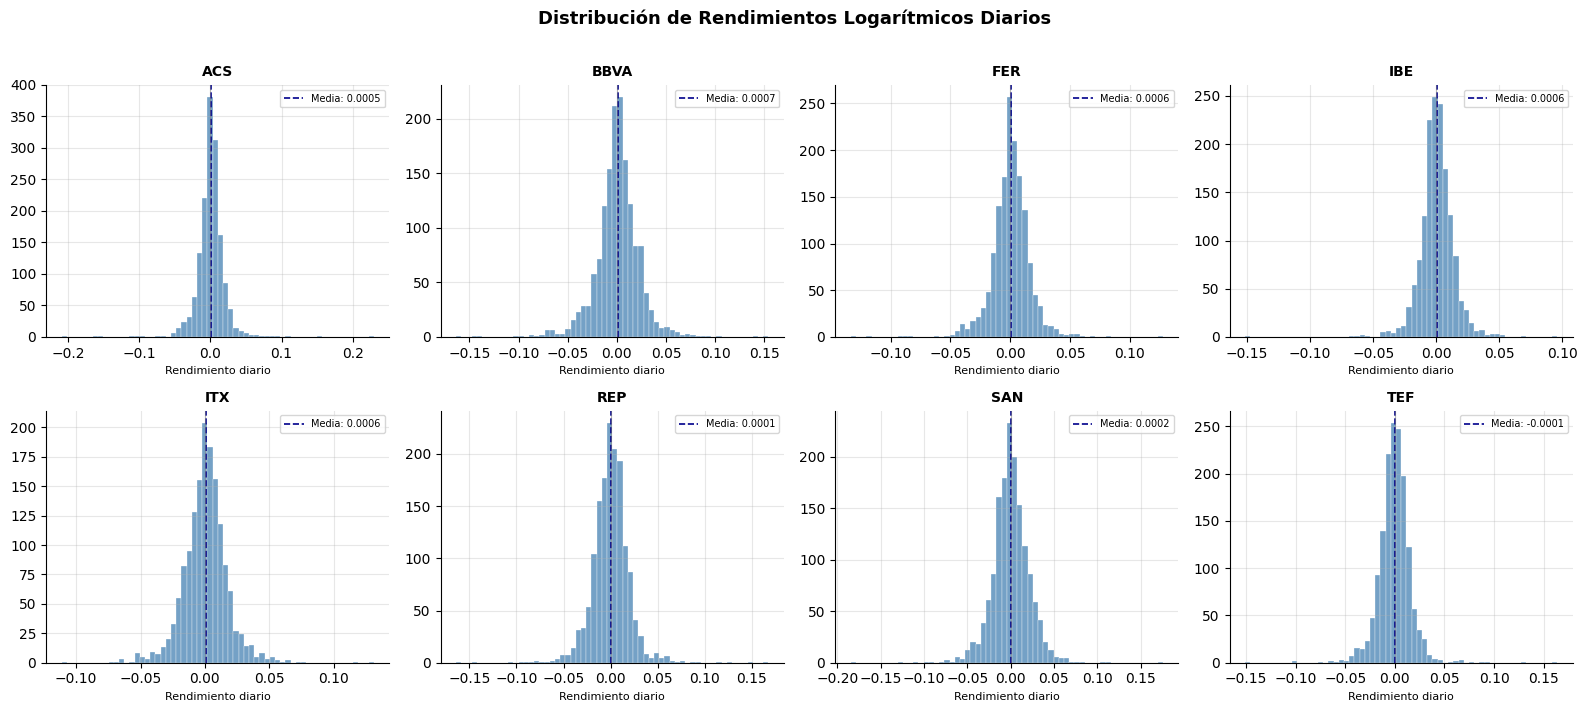

Gráfico guardado: distribucion_rendimientos.png


In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, ticker in enumerate(returns.columns):
    ax = axes[i]
    ret_serie = returns[ticker].dropna()

    # Histograma de rendimientos
    ax.hist(ret_serie, bins=60, color='steelblue', alpha=0.75,
            edgecolor='white', linewidth=0.3)

    # Línea de media
    ax.axvline(ret_serie.mean(), color='darkblue', linestyle='--',
               linewidth=1.2, label=f'Media: {ret_serie.mean():.4f}')

    # Línea de cero
    ax.axvline(0, color='gray', linestyle='-', linewidth=0.8, alpha=0.5)

    ax.set_title(ticker.replace('.MC', ''), fontsize=10, fontweight='bold')
    ax.set_xlabel('Rendimiento diario', fontsize=8)
    ax.legend(fontsize=7)

plt.suptitle('Distribución de Rendimientos Logarítmicos Diarios',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('distribucion_rendimientos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: distribucion_rendimientos.png')


## 8. Estadísticas descriptivas anualizadas

Calculamos las métricas estadísticas clave que se mostrarán en el panel
EDA del dashboard del Proyecto Athena.

In [12]:
# Calcular estadísticas anualizadas
stats = pipeline.compute_annualized_stats(returns)

print('Estadísticas descriptivas anualizadas (252 días hábiles):')
print('=' * 75)
print(stats.to_string())


16:07:32  [INFO]  Calculando estadísticas anualizadas...


Estadísticas descriptivas anualizadas (252 días hábiles):
         Rendimiento anual (%)  Volatilidad anual (%)  Ratio de Sharpe  Asimetría  Curtosis  Máx. Drawdown (%)
Ticker                                                                                                        
ACS.MC                 12.9500                32.9000           0.3936    -0.1164   25.2851           -73.0900
BBVA.MC                17.0300                36.4500           0.4672    -0.3392    7.2438           -64.4500
FER.MC                 16.0700                25.5000           0.6302    -0.5550    9.9733           -44.4100
IBE.MC                 14.6500                21.4000           0.6846    -0.8087   14.2162           -29.3300
ITX.MC                 16.3300                27.6900           0.5897     0.2312    5.7504           -43.5200
REP.MC                  2.2400                33.2600           0.0673     0.1081   10.7022           -67.7200
SAN.MC                  5.6700                35.5000 

### Visualización — Mapa de calor de correlaciones entre activos

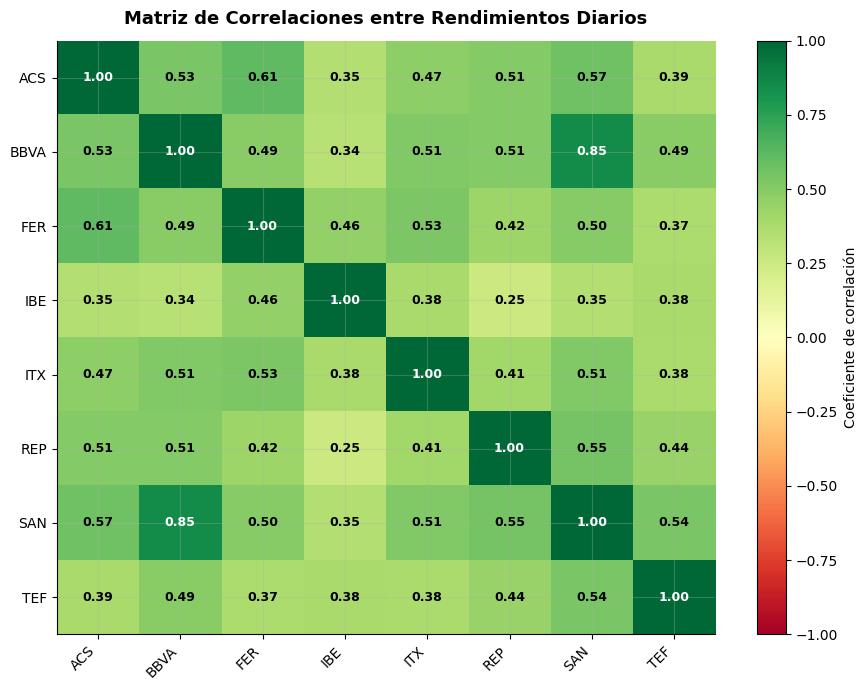

Gráfico guardado: matriz_correlaciones.png


In [13]:
# Matriz de correlaciones entre rendimientos diarios
corr_matrix = returns.corr()

# Renombrar columnas para el gráfico (sin sufijo .MC)
labels = [t.replace('.MC', '') for t in corr_matrix.columns]

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(corr_matrix.values, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')

# Anotaciones con los valores de correlación
for i in range(len(labels)):
    for j in range(len(labels)):
        val = corr_matrix.values[i, j]
        color = 'white' if abs(val) > 0.65 else 'black'
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=9, color=color, fontweight='bold')

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(labels, fontsize=10)
ax.set_title('Matriz de Correlaciones entre Rendimientos Diarios',
             fontsize=13, fontweight='bold', pad=12)

plt.colorbar(im, ax=ax, label='Coeficiente de correlación')
plt.tight_layout()
plt.savefig('matriz_correlaciones.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: matriz_correlaciones.png')


## 9. Resumen y outputs para el Hito 4

El pipeline del Hito 3 produce dos DataFrames que son el input directo
del **Módulo de Optimización de Markowitz (Hito 4)**:

| Output | Variable | Shape | Descripción |
|--------|----------|-------|-------------|
| Precios ajustados | `prices` | (N_días, N_activos) | Input para el preprocesado (Hito siguiente) |
| Rendimientos log. | `returns` | (N_días-1, N_activos) | Input directo para Markowitz (Hito 4) |

### Cómo usar estos outputs en el Hito 4

```python
# Hito 4 — Optimización de Markowitz
# Vector de rendimientos esperados (anualizado)
mu    = returns.mean() * 252

# Matriz de covarianzas (anualizada)
sigma = returns.cov() * 252

# → Minimizar la varianza de la cartera sujeto a restricciones de pesos
# → scipy.optimize.minimize(fun=portfolio_variance, constraints=...)
```

In [14]:
print('=' * 65)
print('  RESUMEN DEL HITO 3 — Adquisición de Datos')
print('=' * 65)
print(f'  Activos en cartera   : {len(returns.columns)}')
print(f'  Período descargado   : {prices.index.min().date()} → {prices.index.max().date()}')
print(f'  Días de cotización   : {len(prices)}')
print(f'  Observaciones retorn.: {len(returns)}')
print(f'  Nulos en prices      : {prices.isna().sum().sum()}')
print(f'  Nulos en returns     : {returns.isna().sum().sum()}')
print()
print('  Variables listas para Hito 4:')
print(f'    prices.shape  = {prices.shape}')
print(f'    returns.shape = {returns.shape}')
print()
print('  Archivos CSV generados en data/cache/:')
if Path('data/cache').exists():
    for f in sorted(Path('data/cache').iterdir()):
        size_kb = f.stat().st_size / 1024
        print(f'    {f.name:<55} ({size_kb:.1f} KB)')
print('=' * 65)


  RESUMEN DEL HITO 3 — Adquisición de Datos
  Activos en cartera   : 8
  Período descargado   : 2019-01-02 → 2024-12-30
  Días de cotización   : 1536
  Observaciones retorn.: 1535
  Nulos en prices      : 0
  Nulos en returns     : 0

  Variables listas para Hito 4:
    prices.shape  = (1536, 8)
    returns.shape = (1535, 8)

  Archivos CSV generados en data/cache/:
    prices_raw_2019-01-01_2024-12-31_1d.csv                 (238.7 KB)
    returns_2019-01-01_2024-12-31_1d.csv                    (273.2 KB)
